# Etapa 5 — Avaliação Comparativa, Diagnóstico de Resíduos e Interpretação

Neste notebook, consolidamos os resultados analíticos finais:
1. **Tabela Comparativa Geral**: Baselines vs Random Forest vs Rede Neural (MLP).
2. **Análise de Resíduos**: normalidade, variância e ausência de viés sistemático.
3. **Importância das Variáveis (Permutation Importance)** no conjunto de teste independente.
4. **Investigação do Efeito de Regressão à Média**: correlação entre a pontuação no pré-teste e o ganho subsequente.

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from wordgen.modelagem.persistencia import carregar_artefato_modelo

REPORTS_DIR = Path("reports/modelagem") if Path("reports/modelagem").exists() else Path("../../reports/modelagem")

# Carrega métricas consolidadas
df_comp = pd.read_csv(REPORTS_DIR / "metricas" / "metricas_comparativas_gerais.csv")
display(df_comp)

,Cenário,Modelo,MAE,RMSE,R²,Média Real,Média Prevista
0,Vocabulário — Experimento A (Acadêmico),Baseline 1 (Ganho Zero),4.555700,6.137100,-0.009000,0.580200,0.000000
1,Vocabulário — Experimento A (Acadêmico),Baseline 2 (Média Treino),4.531300,6.109900,-0.000100,0.580200,0.639000
2,Vocabulário — Experimento A (Acadêmico),Random Forest,4.366900,5.766500,0.109200,0.580200,0.580100
3,Vocabulário — Experimento A (Acadêmico),Rede Neural (MLP),4.307644,5.691106,0.132311,0.580153,0.658742
4,Vocabulário — Experimento B (Acadêmico + Demog...,Baseline 1 (Ganho Zero),4.555700,6.137100,-0.009000,0.580200,0.000000
5,Vocabulário — Experimento B (Acadêmico + Demog...,Baseline 2 (Média Treino),4.531300,6.109900,-0.000100,0.580200,0.639000
6,Vocabulário — Experimento B (Acadêmico + Demog...,Random Forest,4.335400,5.732500,0.119600,0.580200,0.567700
7,Vocabulário — Experimento B (Acadêmico + Demog...,Rede Neural (MLP),4.676855,6.024719,0.027602,0.580153,0.893058
8,TDE II — Experimento A (Acadêmico),Baseline 1 (Ganho Zero),5.770800,9.324600,-0.001000,-0.293600,0.000000
9,TDE II — Experimento A (Acadêmico),Baseline 2 (Média Treino),5.799500,9.329100,-0.002000,-0.293600,0.120300


## 5.1. Comparação Visual de Desempenho (MAE e RMSE)

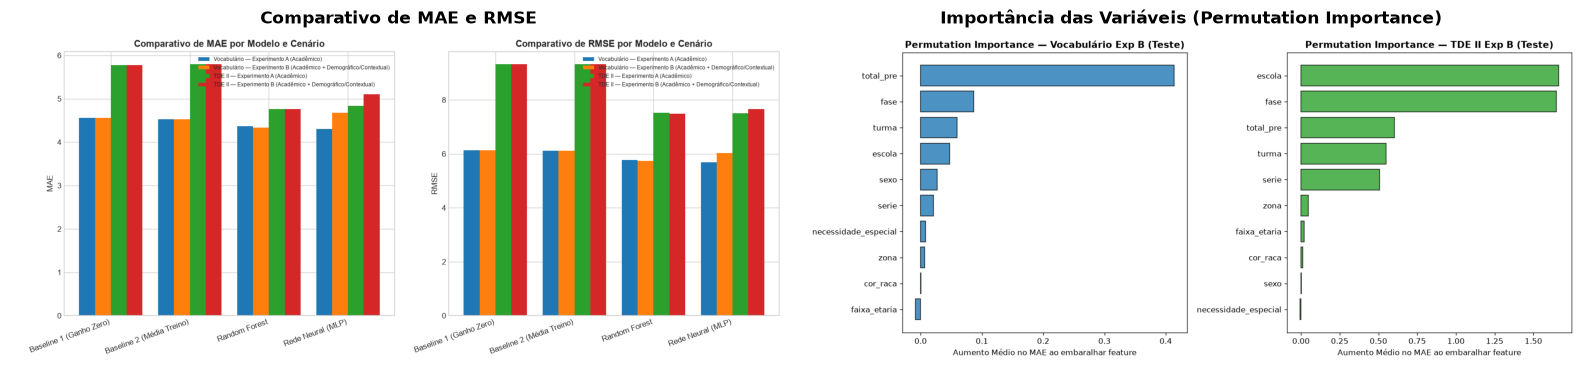

In [2]:
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
img_comp = mpimg.imread(REPORTS_DIR / "graficos" / "comparacao_metricas_mae_rmse.png")
axes[0].imshow(img_comp)
axes[0].axis('off')
axes[0].set_title("Comparativo de MAE e RMSE", fontweight="bold")

img_perm = mpimg.imread(REPORTS_DIR / "graficos" / "importancia_features_permutation.png")
axes[1].imshow(img_perm)
axes[1].axis('off')
axes[1].set_title("Importância das Variáveis (Permutation Importance)", fontweight="bold")

plt.tight_layout()
plt.show()

## 5.2. Diagnóstico de Resíduos e Efeito de Regressão à Média

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
img_res = mpimg.imread(REPORTS_DIR / "graficos" / "residuos_vocabulario.png")
axes[0].imshow(img_res)
axes[0].axis('off')
axes[0].set_title("Distribuição de Resíduos — Vocabulário", fontweight="bold")

img_reg = mpimg.imread(REPORTS_DIR / "graficos" / "efeito_regressao_media.png")
axes[1].imshow(img_reg)
axes[1].axis('off')
axes[1].set_title("Relação entre Pontuação Pré e Ganho", fontweight="bold")

plt.tight_layout()
plt.show()

## 5.3. Conclusão Metodológica

1. **Comparação com os baselines**: os Random Forests superaram os baselines nos quatro cenários. Entre os MLPs, o resultado do Vocabulário/Experimento B não superou a média de treino em MAE.
2. **Desempenho no TDE II**: o Random Forest do Experimento B obteve $R^2 = 0{,}3555$ e MAE de $4{,}7578$; o MLP atualizado obteve $R^2 = 0{,}3250$ e MAE de $5{,}1011$.
3. **Desempenho no Vocabulário**: o Random Forest do Experimento B obteve $R^2 = 0{,}1196$ e MAE de $4{,}3354$; o MLP atualizado obteve $R^2 = 0{,}0276$ e MAE de $4{,}6769$.
4. **Efeito do Pré-teste**: A variável mais preditiva foi `total_pre` (evidenciando regressão à média / espaço para ganho pedagógico).
5. **Limite do Experimento B**: `dim_aluno` agrega dados de múltiplas fases e não comprova a disponibilidade de cada atributo antes da previsão de cada observação. A comparação A/B é exploratória até que features point-in-time sejam validadas.